# CV Part: Face Detection + Our CNN Emotion Model
Member: Wardah Amir

This notebook joins the whole pipeline:

**Photo -> OpenCV face detection -> crop 48x48 grayscale -> our CNN (from Kainat) -> emotion on the image**

Before you start, get these two files from Kainat: `emotion_cnn.keras` and `classes.json`.

**Run the cells from top to bottom.**

## 1. Load our trained CNN
A file window will open: select **both** `emotion_cnn.keras` and `classes.json`.

In [21]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from tensorflow import keras

# Files are already in the workspace, loading them directly
model = keras.models.load_model("emotion_cnn.keras")
classes = json.load(open("classes.json"))
print("Model loaded. Classes:", classes)

Model loaded. Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 2. Face detection and emotion prediction functions
Face detection uses the OpenCV Haar Cascade. Each face is cropped, converted to 48x48 grayscale (same as FER-2013) and passed to the CNN.

In [22]:
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def detect_faces(img, size=48):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    boxes = face_cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40)
    )
    if len(boxes) > 1:
        boxes = [max(boxes, key=lambda b: b[2] * b[3])]   # sirf sab se bara chehra rakho
    faces = []
    for (x, y, w, h) in boxes:
        face48 = cv2.resize(gray[y:y+h, x:x+w], (size, size))
        faces.append({"box": (int(x), int(y), int(w), int(h)),
                      "gray48": face48,
                      "color": img[y:y+h, x:x+w]})
    return faces

def predict_emotion(face48):
    x = face48.astype("float32") / 255.0
    x = x.reshape(1, 48, 48, 1)
    probs = model.predict(x, verbose=0)[0]
    i = int(probs.argmax())
    return classes[i], float(probs[i]), probs

def analyze_image(path):
    """Full pipeline: returns the annotated image and the list of faces with predictions."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError("Image could not be read: " + path)
    faces = detect_faces(img)
    out = img.copy()
    for f in faces:
        label, conf, probs = predict_emotion(f["gray48"])
        f["emotion"], f["confidence"], f["probs"] = label, conf, probs
        x, y, w, h = f["box"]
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(out, label + " " + str(int(conf * 100)) + "%",
                    (x, max(y - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.8, (0, 255, 0), 2)
    return out, faces

## 3. Test on your photos
Upload **5 to 6 photos** with different expressions (happy, sad, surprised, angry, neutral...). Use clear, front-facing photos with good light. Take screenshots of this output for the milestone.

Photos found: ['pexels-chirgoza-31619364.jpg', 'pexels-cristianmuduc-8424626.jpg', 'pexels-krivitskiy-10855248.jpg', 'pexels-nicola-barts-7927526.jpg', 'pexels-olly-3812726.jpg']


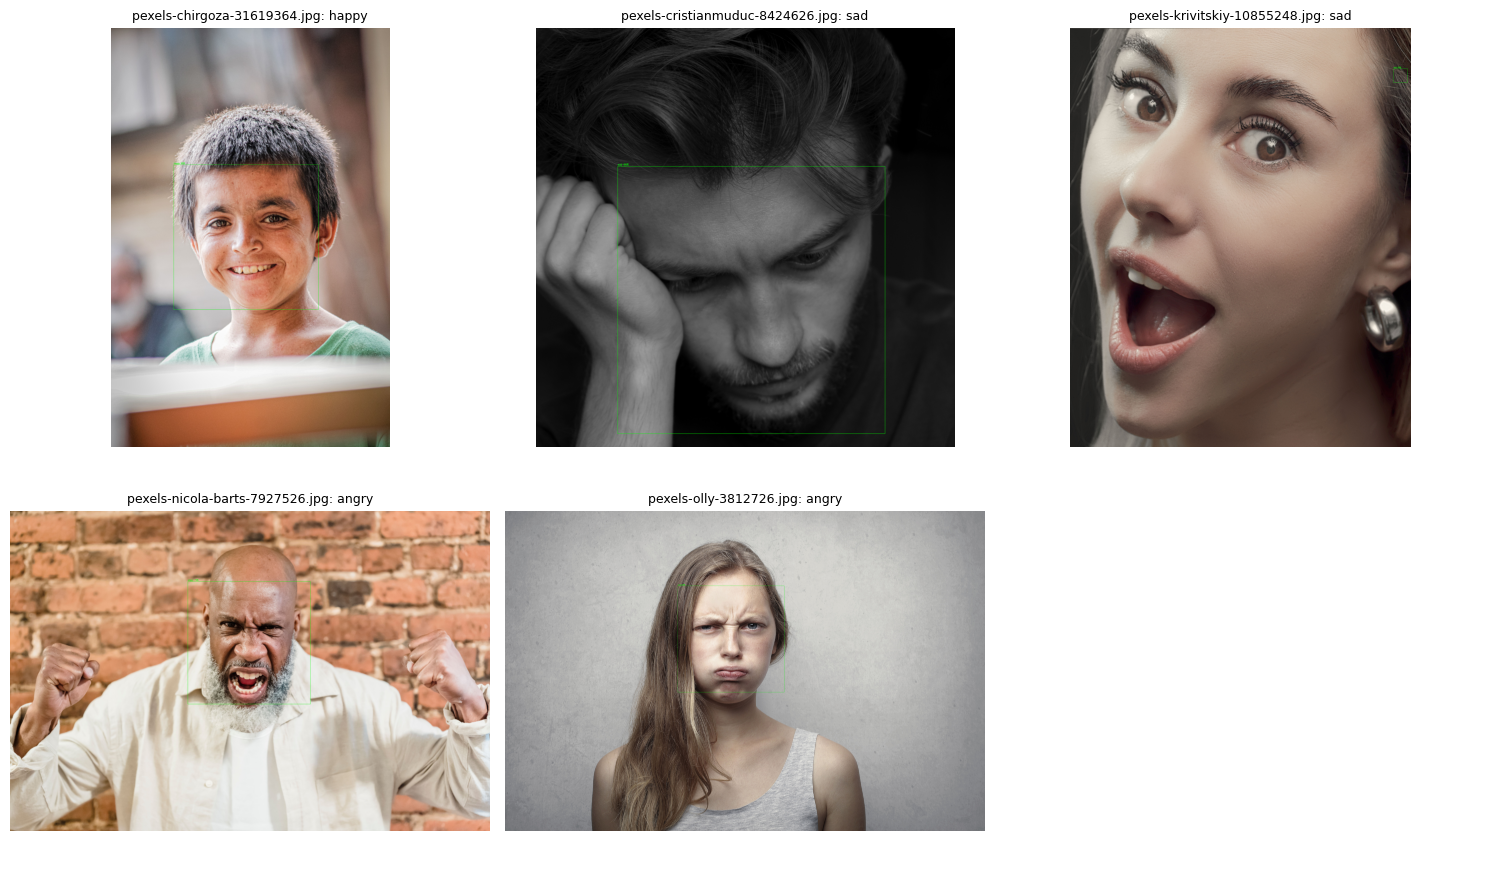

In [23]:
import os

# Agar nayi photos upload karni hon to neeche wali line ka # hata dein:
# photos = files.upload()

# Folder mein pehle se maujood photos khud utha leta hai ("(1)" wale duplicate chhod deta hai)
names = sorted(f for f in os.listdir(".")
               if f.lower().endswith((".jpg", ".jpeg", ".png")) and " (" not in f)
print("Photos found:", names)

cols = min(3, len(names))
rows = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.5 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, name in zip(axes, names):
    out, faces = analyze_image(name)
    ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    ax.axis("off")
    if len(faces) == 0:
        ax.set_title(name + ": no face found", fontsize=9)
    else:
        ax.set_title(name + ": " + ", ".join(f["emotion"] for f in faces), fontsize=9)
for ax in axes[len(names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Look at one photo in detail
Shows the cropped 48x48 face and the model's probability for each emotion.

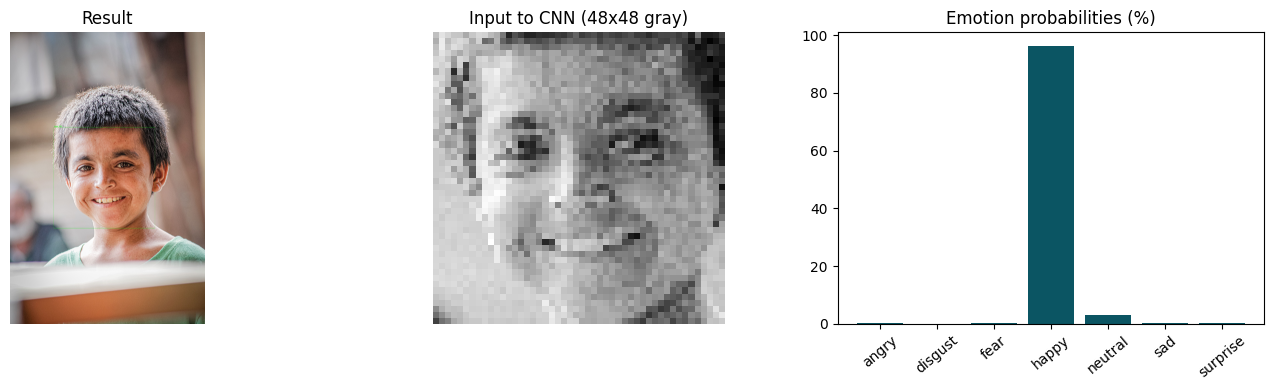

In [24]:
name = names[0]          # change the number to look at another photo
out, faces = analyze_image(name)

if len(faces) == 0:
    print("No face found in", name)
else:
    f = faces[0]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); axes[0].set_title("Result"); axes[0].axis("off")
    axes[1].imshow(f["gray48"], cmap="gray"); axes[1].set_title("Input to CNN (48x48 gray)"); axes[1].axis("off")
    axes[2].bar(classes, f["probs"] * 100, color="#0B5563")
    axes[2].set_title("Emotion probabilities (%)")
    axes[2].tick_params(axis="x", rotation=40)
    plt.tight_layout()
    plt.show()

## 5. Optional: compare our CNN with DeepFace
DeepFace is a pretrained model, used here only as a comparison. Skip this part if the install causes problems.

In [25]:
!pip install -q deepface tf-keras

In [26]:
from deepface import DeepFace
import pandas as pd

rows = []
for name in names:
    img = cv2.imread(name)
    faces = detect_faces(img)
    if len(faces) == 0:
        rows.append({"Photo": name, "Our CNN": "no face", "DeepFace": "no face"})
        continue
    f = faces[0]
    ours, _, _ = predict_emotion(f["gray48"])
    res = DeepFace.analyze(f["color"], actions=["emotion"],
                           detector_backend="skip", enforce_detection=False)
    if isinstance(res, list):
        res = res[0]
    rows.append({"Photo": name, "Our CNN": ours, "DeepFace": res["dominant_emotion"]})

display(pd.DataFrame(rows))

,Photo,Our CNN,DeepFace
0,pexels-chirgoza-31619364.jpg,happy,happy
1,pexels-cristianmuduc-8424626.jpg,sad,fear
2,pexels-krivitskiy-10855248.jpg,sad,fear
3,pexels-nicola-barts-7927526.jpg,angry,angry
4,pexels-olly-3812726.jpg,angry,angry


## Notes for the report
- Haar Cascade works best on front-facing faces with good light. It can miss side faces, small faces or dark photos. Mention this as a limitation.
- Our CNN is trained on FER-2013, so photos with strong emotions and clear faces work best.
- Real-time webcam does not work inside Colab. For a live demo, run the same functions on a laptop with `cv2.VideoCapture(0)`.